<a href="https://colab.research.google.com/github/jeanmw98/2026_Intro_Python/blob/main/Rhone_Na_SO4_analysis_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sodium and sulphate in the River Rhône (NADUF station CH-39)

Group 5 : Ciaran Keegan, Peter Matta, Jean-Michel Wieland

**Course assignment 1 – original analysis of a solute dataset**

This notebook compares two periods (1977–1999 and 2000–2022) and two seasons (October–March and April–September).

**Research question:** To what extent can hydrological variability explain the contrasting evolution of sodium and sulphate concentrations in the river Rhône?


## 0. Setup

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
np.random.seed(42)                       # reproducibility (only used if bootstrapping is added)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

FIG_DIR = "figures"                      # all figures are also saved here (download from the Colab file browser)
os.makedirs(FIG_DIR, exist_ok=True)

def with_gaps(d, max_gap="60D"):
    # Insert NaN rows where consecutive samples are > max_gap apart, so that lines are not drawn across data gaps.
    d = d.sort_values("date").reset_index(drop=True)
    gap = d["date"].diff() > pd.Timedelta(max_gap)
    blanks = pd.DataFrame({"date": d.loc[gap, "date"] - pd.Timedelta("1D")})
    return pd.concat([d, blanks]).sort_values("date").reset_index(drop=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 2.2.3 | numpy 2.4.6 | seaborn 0.13.2


## 1. Data import and preparation

The sheet `samples` of the NADUF Excel file has a header row, a **units row** directly below it, and many empty trailing columns. Each row is a **composite sample** collected proportionally to discharge over `duration` hours (mostly 168 h or 336 h) and ending at `date_end`. `mean_discharge` is the mean discharge over the same period, so concentration and discharge refer to the same time window – this is more consistent than the instantaneous grab samples of Plynlimon.

> **Data gap:** the file contains no samples for 1983–1985 (see the printout below). Lines in the figures are therefore interrupted there, and trend tests use only the years that exist.

Preparation steps:
1. skip the units row and drop empty columns;
2. convert all measurements to numbers (blanks → `NaN`);
3. use the **mid-point** of the sampling period as the sample date;
4. add `logQ` (log₁₀ of discharge), `season` (same definition as in the class exercise) and `period`.

In [ ]:
DATA_FILE = "CH-39.xlsx"

if not os.path.exists(DATA_FILE):                                               # Colab: ask the user to upload the file
    try:
        from google.colab import files
        print("Please select the file CH-39.xlsx")
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Put CH-39.xlsx in the same folder as this notebook.")

# --- read the data (row 0 = header, row 1 = units)
raw   = pd.read_excel(DATA_FILE, sheet_name="samples", skiprows=[1])
units = pd.read_excel(DATA_FILE, sheet_name="samples", nrows=1).iloc[0]         # the units row, kept for reference
raw   = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]          # drop empty columns

meta_cols = ["station", "status_number", "remark", "lab_number", "date_end"]
num_cols  = [c for c in raw.columns if c not in meta_cols]
raw[num_cols] = raw[num_cols].apply(pd.to_numeric, errors="coerce")
raw["date_end"] = pd.to_datetime(raw["date_end"])

# --- derived variables
SPLIT_YEAR = 2000                                                               # boundary between the two periods
df = raw.dropna(subset=["date_end", "mean_discharge", "duration"]).copy()       # duration is needed for the mid-point date
df["date"]   = df["date_end"] - pd.to_timedelta(df["duration"] / 2, unit="h")   # mid-point of sampling period
df["year"]   = df["date"].dt.year
df["month"]  = df["date"].dt.month
df["logQ"]   = np.log10(df["mean_discharge"])
df["season"] = np.where(df["month"].isin([10, 11, 12, 1, 2, 3]), "winter (Oct–Mar)", "summer (Apr–Sep)")
df["period"] = np.where(df["year"] < SPLIT_YEAR, f"1977–{SPLIT_YEAR-1}", f"{SPLIT_YEAR}–2022")
PERIODS = [f"1977–{SPLIT_YEAR-1}", f"{SPLIT_YEAR}–2022"]
SEASONS = ["winter (Oct–Mar)", "summer (Apr–Sep)"]

# --- main solutes of interest and reference solutes seen in class
TARGETS = {"sodium": "Na",
           "chloride": "Cl",
           "sulphate": "SO$_4$"}

REFERENCE = {"nitrate": "NO$_3$-N"}
UNIT       = {"sodium": "mg/L", "sulphate": "mg SO$_4$/L", "chloride": "mg/L", "nitrate": "mg N/L", "calcium": "mg/L"}
LABEL      = {**TARGETS, **REFERENCE, "calcium": "Ca"}

# molar masses [g/mol] to compare solutes on an equivalent (molar) basis
MM = {"sodium": 22.99, "chloride": 35.45, "sulphate": 96.06, "calcium": 40.08}
for k, m in MM.items():
    df[k + "_mmol"] = df[k] / m                                                 # mg/L / (g/mol) = mmol/L

print(f"{len(df)} samples between {df['date'].min():%Y-%m-%d} and {df['date'].max():%Y-%m-%d}")
print(f"Median sampling duration: {df['duration'].median():.0f} h | station code(s): {df['station'].unique()}")
print("\nNumber of valid values per variable:")
print(df[["mean_discharge", "sodium", "sulphate", "chloride", "nitrate", "calcium"]].count().to_string())
# Which years have no samples at all? (important for the interpretation of trends)
missing_years = sorted(set(range(df["year"].min(), df["year"].max() + 1)) - set(df["year"]))
print("\nYears without any sample:", missing_years)
df[["date", "mean_discharge", "sodium", "sulphate", "chloride", "nitrate", "calcium", "season", "period"]].sample(5, random_state=1)

1168 samples between 1977-04-15 and 2022-12-11
Median sampling duration: 336 h | station code(s): ['CH']

Number of valid values per variable:
mean_discharge    1168
sodium            1119
sulphate          1117
chloride          1120
nitrate           1119
calcium           1116

Years without any sample: [1983, 1984, 1985]


,date,mean_discharge,sodium,sulphate,chloride,nitrate,calcium,season,period
457,1995-09-13 07:15:00,475.126566,4.60,39.000,5.600,0.490,44.0880,summer (Apr–Sep),1977–1999
309,1990-01-08 19:15:00,160.527202,5.70,53.600,7.800,0.690,48.8976,winter (Oct–Mar),1977–1999
216,1986-08-11 19:15:00,486.455156,3.80,44.000,5.400,0.270,44.0880,summer (Apr–Sep),1977–1999
969,2015-05-25 07:50:00,419.405826,6.79,46.441,9.418,0.557,49.0980,summer (Apr–Sep),2000–2022
525,1998-04-02 18:45:00,196.870795,7.00,49.700,8.600,0.780,51.3024,summer (Apr–Sep),1977–1999


In [ ]:
# Descriptive statistics by period: do the two periods differ?
summary = (df.groupby("period")[["mean_discharge", "sodium", "sulphate", "chloride", "nitrate"]]
             .agg(["mean", "std", "min", "max"]).round(2))
summary

mean_discharge                         sodium                    \
                    mean     std     min     max   mean   std   min   max   
period                                                                      
1977–1999         376.34  143.20  133.60  846.62   4.89  1.20  2.40  10.1   
2000–2022         322.74  120.98  125.78  781.48   6.93  1.04  4.38  12.1   

          sulphate                     chloride                    nitrate  \
              mean   std    min    max     mean   std   min    max    mean   
period                                                                       
1977–1999    45.14  4.07  31.00  55.00     6.63  1.83  2.60  14.20    0.51   
2000–2022    46.50  3.37  33.39  56.34    10.32  1.76  6.68  19.92    0.72   

                             
            std   min   max  
period                       
1977–1999  0.22  0.05  1.08  
2000–2022  0.20  0.23  1.34

---
## Part 1 – Sources of sodium and sulphate (extends Activity 1)

In the Plynlimon exercise, Cl and Na were used to infer sea-salt inputs. In a Swiss river the same ions can have very different origins. Possible sources to examine (check the literature for the Rhône catchment):

* **Sodium and chloride:** halite (NaCl) – road de-icing salt, industrial discharge, evaporite weathering – or silicate weathering (extra Na).
* **Sulphate:** gypsum/anhydrite dissolution (Ca²⁺ : SO₄²⁻ = 1 : 1), sulphide oxidation, atmospheric deposition, fertilisers.

Tools used here (all on a **molar** basis, because ion ratios are only meaningful in mol):
* **Na : Cl** – a ratio ≈ 1 indicates a halite source; a ratio > 1 indicates Na from another source (e.g. silicate weathering).
* **Ca : SO₄** – a ratio ≈ 1 would indicate gypsum; excess Ca points to carbonate weathering.

### Figure 1 – Temporal evolution

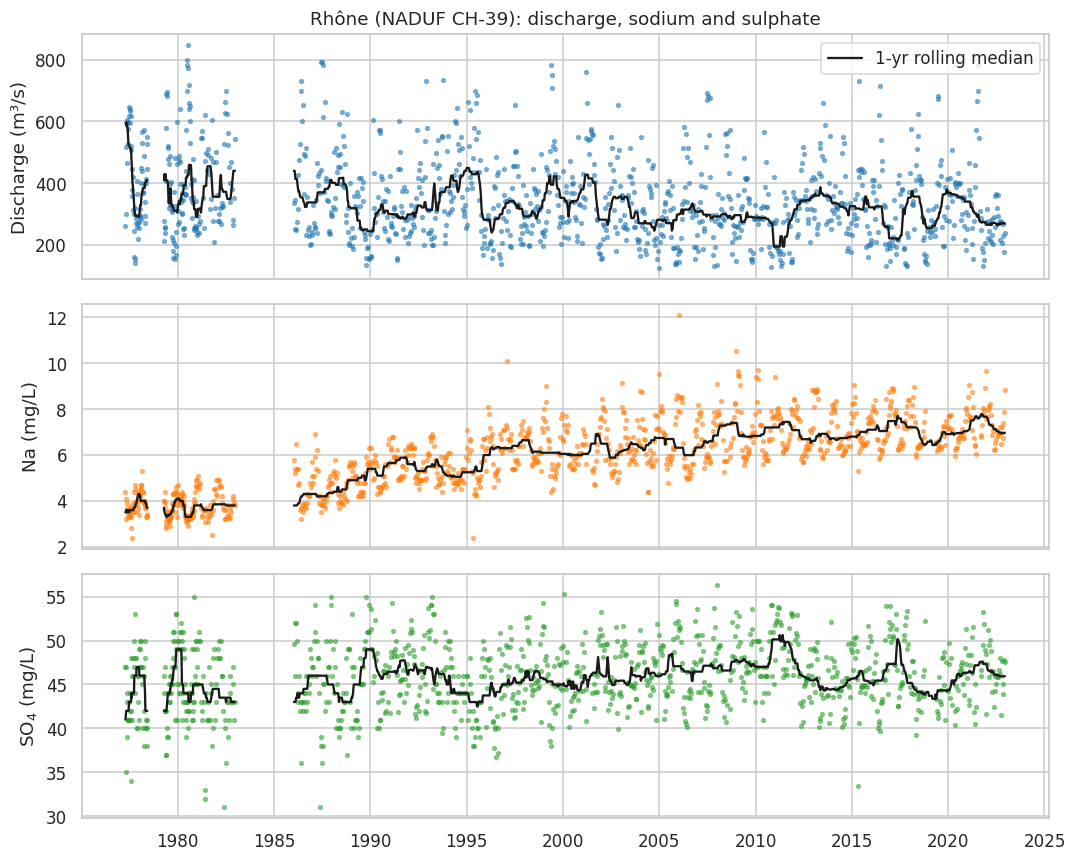

In [ ]:
# Fig. 1 - time series of discharge, Na and SO4 (dots = samples, line = 1-year rolling median of ~26 samples)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
series = [("mean_discharge", "Discharge (m³/s)", "tab:blue"),
          ("sodium",   "Na (mg/L)",       "tab:orange"),
          ("sulphate", "SO$_4$ (mg/L)",   "tab:green")]
d = df.sort_values("date").reset_index(drop=True)
for ax, (col, lab, colr) in zip(axes, series):
    ax.plot(d["date"], d[col], "o", ms=2.5, color=colr, alpha=.5)
    roll = d.assign(r=d[col].rolling(26, center=True, min_periods=10).median())
    roll = with_gaps(roll)
    ax.plot(roll["date"], roll["r"], color="k", lw=1.5, label="1-yr rolling median")
    ax.set_ylabel(lab)
axes[0].legend(loc="upper right")
axes[0].set_title("Rhône (NADUF CH-39): discharge, sodium and sulphate")
axes[-1].set_xlabel("")
plt.tight_layout(); save_fig("fig1_timeseries"); plt.show()

1. Comparison between the two periods

Through these graphs, we can observe that the average river discharge decreases from about 376 m³/s to 323 m³/s between the two periods.

The mean sodium concentration increases from 4.89 to 6.93 mg/L (about 42%). And the mean sulphate concentration changes very little, from 45.14 to 46.50 mg/L (so about 3%).

2. Analysis

Lower discharge can lead to higher concentrations because there is less water to dilute dissolved substances. However, this does not explain why sodium increases much more than sulphate.

The increase in sodium throughout the years may be exlpained by the increase of sodium inputs, for example from road salt or wastewater. The city of Geneva went through exponential growth, with a population of 330'00 from 1977 uptil 627'000 in 2022 (Geneve, Switzerland Population "populationstat.com") leading to more road construction and waste production.

The gap in 1983–1985 represents missing observations from the CH-39 dataset.

Figure 2 - Concentration Distribution

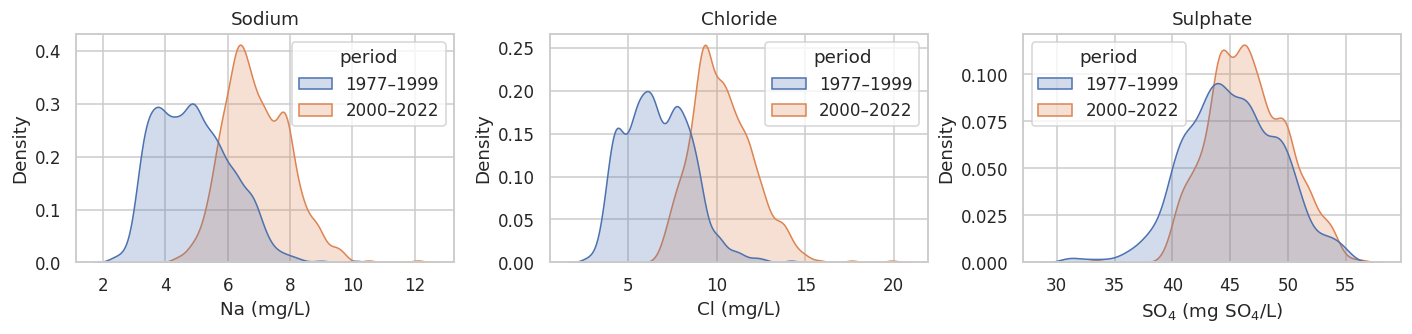

In [ ]:
# Fig. 2 - Concentration distributions between the two periods

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))

for ax, (col, lab) in zip(axes, TARGETS.items()):
    sns.kdeplot(
        data=df,
        x=col,
        hue="period",
        hue_order=PERIODS,
        common_norm=False,
        bw_adjust=.7,
        fill=True,
        alpha=.25,
        ax=ax
    )

    ax.set_xlabel(f"{lab} ({UNIT[col]})")

axes[0].set_title("Sodium")
axes[1].set_title("Chloride")
axes[2].set_title("Sulphate")

plt.tight_layout()
plt.show()

Graph analysis:

The concentration distributions of sodium and chloride shift towards higher values during the second period (2000–2022), indicating an overall increase in their concentrations compared to the first period (1977–1999). On the other hand, the sulphate distributions largely overlap, indicating relatively stable concentrations between the two periods.

Explanation:

The increase in sodium and chloride concentrations could be attributed to human-induced NaCl inputs, such as road de-icing salts, industrial discharges and domestic wastewater (CIPEL, 2022). In contrast, the relative stability of sulphate concentrations could be explained by more consistent geogenic inputs, particularly through the dissolution of gypsum and anhydrite within the Rhône catchment (Zobrist, 2011), potentially combined with the buffering effect of Lake Geneva. Nonetheless, these distributions only illustrate changes in concentration and variability over time and do not confirm the origin of these solutes.

### Figure 3 – Potential solute sources

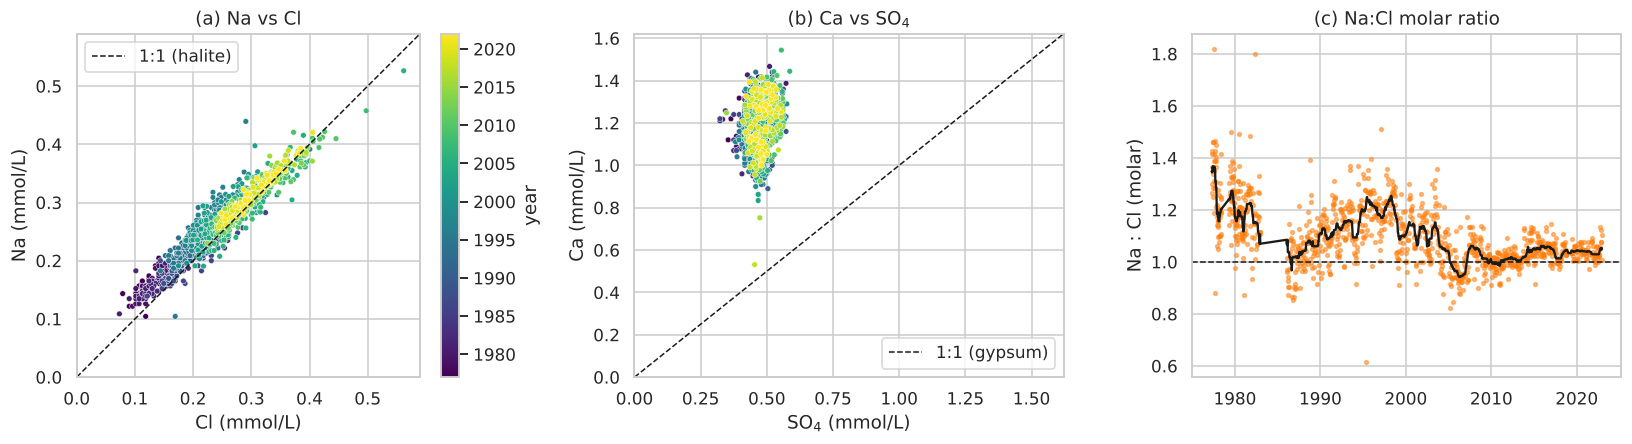

Median molar Na:Cl  = 1.07
Median molar Ca:SO4 = 2.51
Correlation (Pearson r) Na–Cl : 0.96
Correlation (Pearson r) SO4–Ca: 0.26


In [ ]:
# Fig. 3 - ion ratios: (a) Na vs Cl, (b) SO4 vs Ca, (c) Na:Cl molar ratio through time
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) Na vs Cl (mmol/L) - halite would fall on the 1:1 line
ax = axes[0]
sns.scatterplot(data=df, x="chloride_mmol", y="sodium_mmol", hue="year", palette="viridis", s=14, ax=ax, legend=False)
lim = [0, np.nanmax(df[["chloride_mmol", "sodium_mmol"]].values) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="1:1 (halite)")
ax.set(xlabel="Cl (mmol/L)", ylabel="Na (mmol/L)", title="(a) Na vs Cl", xlim=lim, ylim=lim); ax.legend()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(df["year"].min(), df["year"].max()))
plt.colorbar(sm, ax=ax, label="year")

# (b) SO4 vs Ca (mmol/L) - gypsum would fall on the 1:1 line
ax = axes[1]
sns.scatterplot(data=df, x="sulphate_mmol", y="calcium_mmol", hue="year", palette="viridis", s=14, ax=ax, legend=False)
lim = [0, np.nanmax(df[["sulphate_mmol", "calcium_mmol"]].values) * 1.05]
ax.plot(lim, lim, "k--", lw=1, label="1:1 (gypsum)")
ax.set(xlabel="SO$_4$ (mmol/L)", ylabel="Ca (mmol/L)", title="(b) Ca vs SO$_4$", xlim=lim, ylim=lim); ax.legend()

# (c) molar Na:Cl through time
ax = axes[2]
ratio = (df["sodium_mmol"] / df["chloride_mmol"])
r_df = with_gaps(df.assign(ratio=ratio).sort_values("date").reset_index(drop=True))
ax.plot(r_df["date"], r_df["ratio"], "o", ms=2.5, alpha=.5, color="tab:orange")
ax.plot(r_df["date"], r_df["ratio"].rolling(26, center=True, min_periods=10).median(), "k-", lw=1.5)
ax.axhline(1, color="k", ls="--", lw=1)
ax.set(ylabel="Na : Cl (molar)", title="(c) Na:Cl molar ratio")
ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator(10))
plt.tight_layout(); save_fig("fig3_ion_ratios"); plt.show()

print("Median molar Na:Cl  =", round(ratio.median(), 2))
print("Median molar Ca:SO4 =", round((df["calcium_mmol"] / df["sulphate_mmol"]).median(), 2))
print("Correlation (Pearson r) Na–Cl :", round(df[["sodium", "chloride"]].corr().iloc[0, 1], 2))
print("Correlation (Pearson r) SO4–Ca:", round(df[["sulphate", "calcium"]].corr().iloc[0, 1], 2))

1. Median molar ratios

The first graph compares the molar concentrations of sodium and chloride to a 1:1 ratio (represented by the dotted line). We can observe that the points are all very close to this line and indeed, the median molar ratio between Na:Cl is 1.07 and has a very strong correlation (0.97)

The second graph compares the molar concentrations of calcium with sulfate to the same 1:1 ratio. We can observe that the points are all closer to calcium, with a ratio between  calcium and sulfate of 2.51 in favor of calcium.

The last graph shows the temporality of the molar ratio between Na and Cl.

2. Analysis

The 1.07 ratio between Na:Cl would mean that the increase of sodium is linked to an imput of NaCl, so by road salts and antropic wastes in the river catchment.

The 2.51 ratio between calcium and sulfate indicates that calcium and sulfate are not related to a same source. It is highly probable that the calcium source is taken directly from the mother rock of this area since the Jura mountain range is highly composed of calcite (CACO3).

Sodium and chloride exhibit a strong positive correlation (r = 0.96), and the Na:Cl molar ratio approaches 1 over time. This is consistent with an increasing contribution from NaCl-related sources, potentially road de-icing salts, wastewater or natural halite dissolution. However, the ratio cannot distinguish these sources. Calcium is present in excess relative to sulphate (median Ca:SO₄ ratio = 2.51), suggesting additional calcium sources such as carbonate weathering. Their weaker correlation (r = 0.26) indicates that gypsum dissolution alone cannot explain their joint variability.

The progressive increase in sodium and chloride concentrations could be partially explained by the location of the Chancy monitoring station downstream of Lake Geneva. Accordingly, CIPEL (2023) reported a substantial increase in chloride within the lake between 1973 and 2016, followed by a period of relative stabilisation until 2021. This increase was primarily associated with industrial activities and the use of road de-icing salts within the catchment. Considering the long residence time of water within Lake Geneva, the accumulation and gradual release of dissolved salts could explain the long-term increase observed at Chancy, as well as its persistence across different seasons.

## Part 2 – Concentration–discharge relationships

The power law $C=aQ^b$ is fitted by linear regression of log-transformed concentration on log-transformed discharge. Negative slopes indicate dilution, positive slopes indicate enrichment, and slopes close to zero indicate weak sensitivity to discharge. The relationships are compared by season and period to distinguish hydrological effects from long-term concentration changes.

The progressive increase in sodium and chloride concentrations could be partially explained by the location of the Chancy monitoring station downstream of Lake Geneva. Accordingly, CIPEL (2023) reported a substantial increase in chloride stocks within the lake between 1973 and 2016, followed by a period of relative stabilisation until 2021. This increase was primarily associated with industrial activities and the use of road de-icing salts within the catchment. Considering the long residence time of water within Lake Geneva, the accumulation and gradual release of dissolved salts could explain the long-term increase observed at Chancy, as well as its persistence across different seasons.

### Figure 3 – Seasonal and historical C–Q relationships

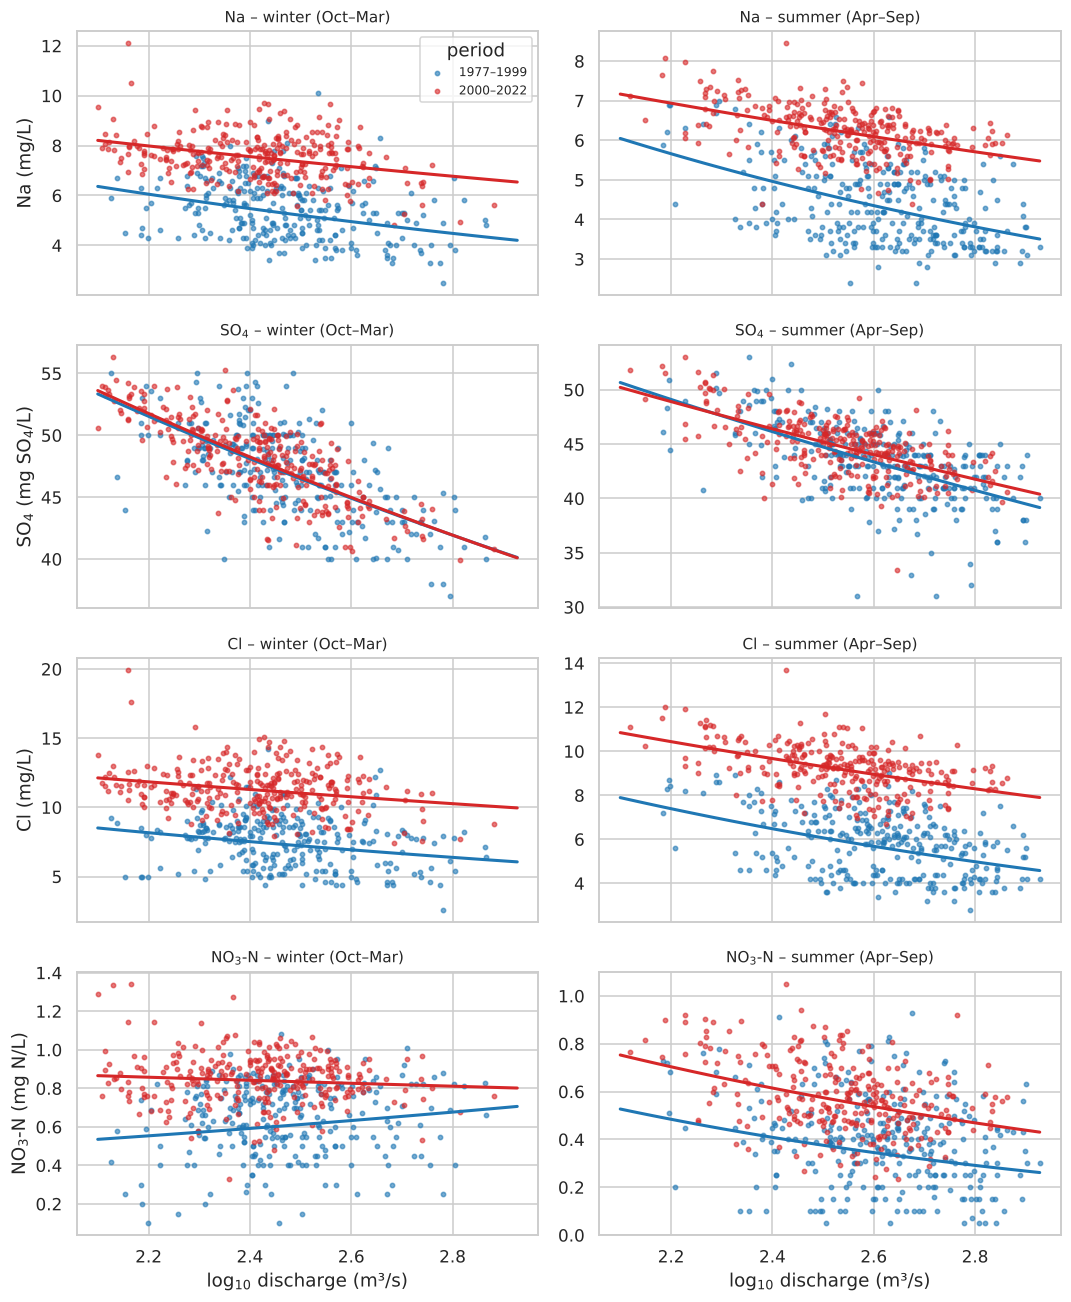

In [ ]:
def cq_fit(sub, col):
    # Power-law C = a * Q^b fitted in log-log space. Returns slope b, 95% CI, R2 and n.
    d = sub[["logQ", col]].dropna()
    d = d[d[col] > 0]
    if len(d) < 10:
        return dict(b=np.nan, ci=np.nan, r2=np.nan, n=len(d), a=np.nan)
    res = stats.linregress(d["logQ"], np.log10(d[col]))
    tcrit = stats.t.ppf(0.975, len(d) - 2)
    return dict(b=res.slope, ci=tcrit * res.stderr, r2=res.rvalue ** 2, n=len(d), a=res.intercept)

solutes_cq = {**TARGETS, **REFERENCE}                     # Na, SO4 + Cl, NO3 as benchmark from class
palette = dict(zip(PERIODS, ["tab:blue", "tab:red"]))

# Fig. 4 - C-Q scatter: rows = solutes, columns = seasons; colour = period; lines = power-law fit per period
fig, axes = plt.subplots(len(solutes_cq), 2, figsize=(10, 3.0 * len(solutes_cq)), sharex=True)
xx = np.linspace(df["logQ"].min(), df["logQ"].max(), 50)
for i, (col, lab) in enumerate(solutes_cq.items()):
    for j, seas in enumerate(SEASONS):
        ax = axes[i, j]
        for per in PERIODS:
            sub = df[(df["season"] == seas) & (df["period"] == per)]
            ax.scatter(sub["logQ"], sub[col], s=8, alpha=.6, color=palette[per], label=per)
            f = cq_fit(sub, col)
            if np.isfinite(f["b"]):
                ax.plot(xx, 10 ** (f["a"] + f["b"] * xx), color=palette[per], lw=2)
        ax.set_ylabel(f"{lab} ({UNIT[col]})" if j == 0 else "")
        ax.set_title(f"{lab} – {seas}", fontsize=10)
        if i == len(solutes_cq) - 1: ax.set_xlabel("log$_{10}$ discharge (m³/s)")
axes[0, 0].legend(title="period", fontsize=8)
plt.tight_layout(); save_fig("fig4_CQ_scatter"); plt.show()

In [ ]:
# Table 1 - C-Q slope b (±95% CI), R2 and sample size for every solute x season x period
rows = []
for col, lab in solutes_cq.items():
    for seas in SEASONS + ["all year"]:
        for per in PERIODS + ["all periods"]:
            sub = df
            if seas != "all year":      sub = sub[sub["season"] == seas]
            if per != "all periods":    sub = sub[sub["period"] == per]
            f = cq_fit(sub, col)
            rows.append(dict(solute=lab.replace("$", "").replace("_", ""), season=seas, period=per, b=f["b"], CI95=f["ci"], R2=f["r2"], n=f["n"]))
cq_table = pd.DataFrame(rows).round(3)
cq_table

,solute,season,period,b,CI95,R2,n
0,Na,winter (Oct–Mar),1977–1999,-0.217,0.077,0.105,267
1,Na,winter (Oct–Mar),2000–2022,-0.119,0.040,0.109,283
2,Na,winter (Oct–Mar),all periods,-0.262,0.058,0.127,550
3,Na,summer (Apr–Sep),1977–1999,-0.286,0.066,0.201,294
4,Na,summer (Apr–Sep),2000–2022,-0.141,0.033,0.207,275
5,Na,summer (Apr–Sep),all periods,-0.332,0.053,0.213,569
6,Na,all year,1977–1999,-0.323,0.047,0.248,561
7,Na,all year,2000–2022,-0.214,0.029,0.276,558
8,Na,all year,all periods,-0.362,0.037,0.252,1119
9,SO4,winter (Oct–Mar),1977–1999,-0.149,0.023,0.381,268


Sodium and sulphate exhibit negative C–Q slopes in both seasons, indicating dilution at higher discharge. Sodium and chloride concentrations are higher in the second period at comparable discharge, suggesting that reduced dilution alone cannot explain their increase. Sodium also exhibits weaker dilution slopes in the recent period (winter: −0.217 to −0.119; summer: −0.286 to −0.141). Sulphate relationships remain comparatively similar between periods. Nitrate shows summer dilution but weak winter relationships, suggesting different seasonal controls. These comparisons are descriptive and do not formally test differences between regression lines.

## Part 3 – Seasonality

### Figure 4 – Monthly discharge and solute concentrations

The lower panels use flow-adjusted concentrations, calculated from a log-concentration regression including discharge and year. Each adjusted concentration is divided by its annual mean to reduce the influence of long-term changes. A value of 1 represents the adjusted annual mean.

In [ ]:

def flow_adjust(data, col):
    # Return flow-adjusted concentration C_adj = C * (Q/Q_median)^(-beta) and the estimated beta.
    d = data[["year", "logQ", col]].dropna()
    d = d[d[col] > 0]
    X = np.column_stack([np.ones(len(d)), d["logQ"] - d["logQ"].median(), d["year"] - 2000])
    coef, *_ = np.linalg.lstsq(X, np.log10(d[col]), rcond=None)
    beta = coef[1]
    adj = data[col] * 10 ** (-beta * (data["logQ"] - data["logQ"].median()))
    return adj, beta


for col in TARGETS:
    df[col + "_adj"], beta = flow_adjust(df, col)
    print(f"{col}: flow exponent = {beta:+.2f}")

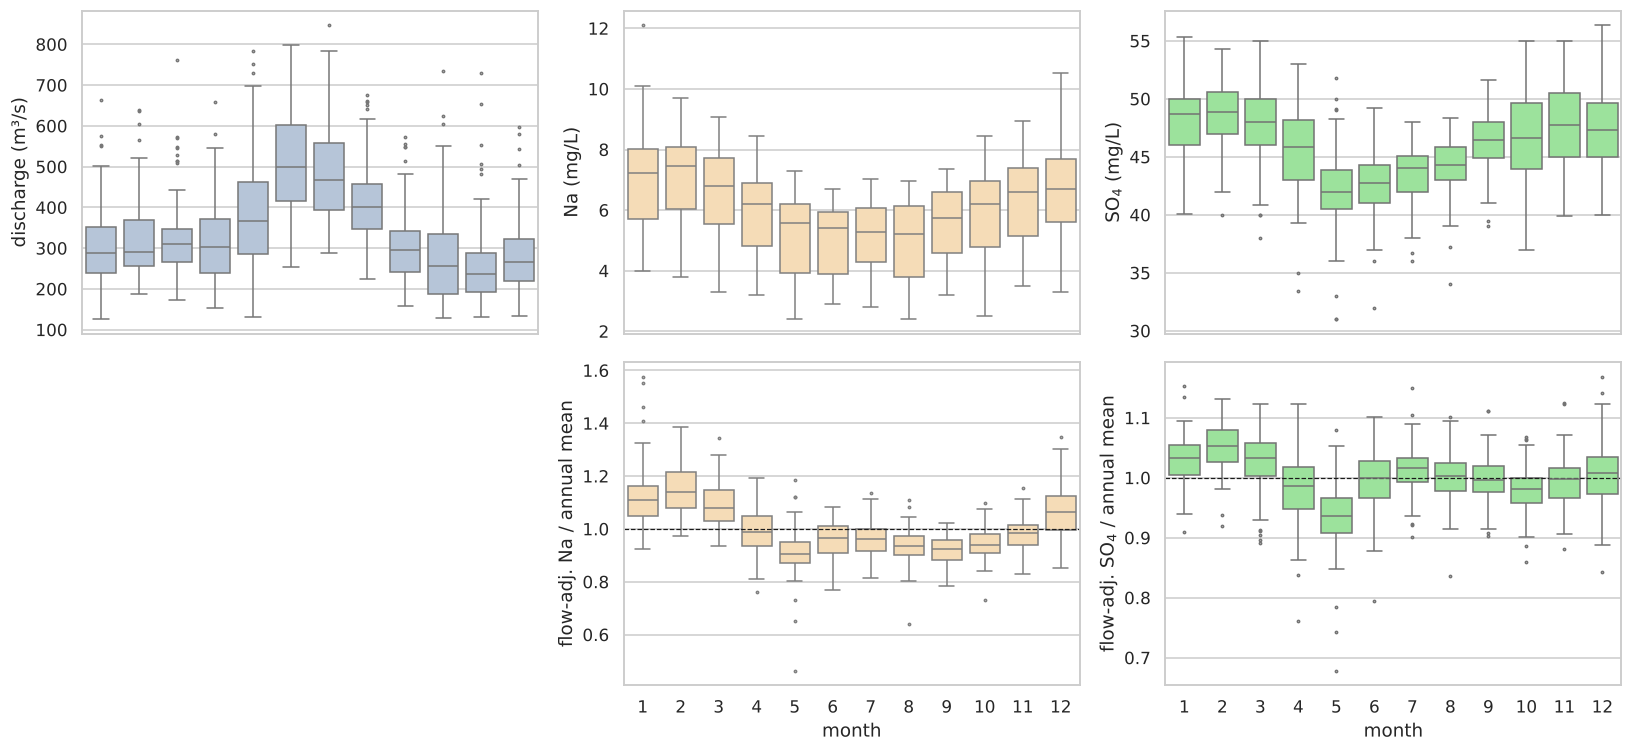

In [ ]:
# Fig. 8 - seasonality
df["Na_rel"]  = df["sodium_adj"]  / df.groupby("year")["sodium_adj"].transform("mean")
df["SO4_rel"] = df["sulphate_adj"] / df.groupby("year")["sulphate_adj"].transform("mean")

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
sns.boxplot(data=df, x="month", y="mean_discharge", color="lightsteelblue", fliersize=1.5, ax=axes[0, 0])
sns.boxplot(data=df, x="month", y="sodium",   color="navajowhite", fliersize=1.5, ax=axes[0, 1])
sns.boxplot(data=df, x="month", y="sulphate", color="lightgreen",  fliersize=1.5, ax=axes[0, 2])
sns.boxplot(data=df, x="month", y="Na_rel",   color="navajowhite", fliersize=1.5, ax=axes[1, 1])
sns.boxplot(data=df, x="month", y="SO4_rel",  color="lightgreen",  fliersize=1.5, ax=axes[1, 2])
axes[0, 0].set_ylabel("discharge (m³/s)"); axes[0, 1].set_ylabel("Na (mg/L)"); axes[0, 2].set_ylabel("SO$_4$ (mg/L)")
axes[1, 1].set_ylabel("flow-adj. Na / annual mean"); axes[1, 2].set_ylabel("flow-adj. SO$_4$ / annual mean")
axes[1, 0].axis("off")
for a in axes[1, 1:]: a.axhline(1, color="k", lw=.8, ls="--")
for a in axes.flat: a.set_xlabel("month")
plt.tight_layout(); save_fig("fig8_seasonality"); plt.show()

Discharge is highest in early summer, consistent with Alpine snow and glacier melt, while sodium and sulphate concentrations are generally lower during the warmer months. After flow adjustment and annual normalisation, sodium retains a clearer winter enrichment signal than sulphate. This suggests that discharge alone does not explain all sodium seasonality, and seasonal inputs such as road salt may contribute. Sulphate seasonality is reduced after adjustment, consistent with a stronger hydrological control. These patterns do not establish the specific sources of either solute.

**Top left:**
This shows the montlhy discharge average for the total sampled data, it shows that there is an increase in discharge during spring to summer. This is consistent with alpine snow and glacial melting.

**Top middle:**
This shows the measured concentrations of sodium in the river for each month. From January to march the sodium values are relatively high, they begin to decrease from April to August and then increase agian from September to December. Possible explination: Dilution from melting events. Input from city (salting), However this does not completely explain the seasonal pattern

**Top right:**
Here we have the measured concentration of sulphate, it follows a similar trend to the sodium where higher concentrations are detected in the winter, decreased concentrations in the spring/ summer, and increasing values approaching the winter again. Possible exlpanation: Dilution from melting events, (to note: decrease in concentration with increase in flow)

**Flow adjustement:**
High discarge with low concntrations, flow adjustment will account for this dilution effect, allowing to investigate if the seasonal pattern remains after accounting for discharge.....

**middle bottom:**
This shows the concentrations of sodium while allowing for flow adjustment. There is still a consistent trend that winter months have higher concentrations and summer months have lower concentrations. Therefore the fluxuation in concentration can not be explained completely by the increase in river discharge. Possible explanation ? road de-icing salt; Ice-melt, snow-melt and rainfall can transport dissolved sodium and chloride into rivers

**Bottom right:**
Before applying the flow adjustment, sulphate concentrations showed a seasonal pattern similar to sodium. After applying the adjustment this trend is much less pronounced. This suggests that the effect of hydrological dilution explains a greater proportion of the observed seasonal variation for sulphate in the river.
this is what i have written. Can we go for a two part discription here, first part speaking about what is actually being seen in the graphs and then the second part of where we discuss explanations in whats going on. Keep my language and only change if nessecary and tell me what you change

## Conclusion

Sodium and sulphate display contrasting temporal behaviours in the Rhône. Both are diluted at higher discharge, but sodium and chloride show higher concentrations in recent decades even at comparable discharge. Their strong correlation and near-equimolar relationship suggest a common NaCl-related contribution, although its origin cannot be confirmed without additional source data. Sulphate concentrations and C–Q relationships remain comparatively stable. Overall, hydrological variability appears to explain part of the observed changes, but additional controls are likely important for sodium.

In [ ]:
# Optional: export the retained C–Q results
os.makedirs("tables", exist_ok=True)
cq_table.to_csv("tables/cq_slopes.csv", index=False)
print("Figures saved in ./figures; C–Q table saved in ./tables")

Eawag: Swiss Federal Institute Of Aquatic Science And Technology, & Federal Office For The Environment (FOEN). (2024). NADUF - National long-term surveillance of Swiss rivers (2024-1) (Version 2024-1). Eawag: Swiss Federal Institute of Aquatic Science and Technology. https://doi.org/10.25678/000C7N